In [1]:
# Some quick installs if running on Colab
%load_ext autoreload
%autoreload 2

# Install latest commit of tinygp (contains necessary bug fixes)
try:
    import tinygp
except ImportError:
    !pip install git+https://github.com/dfm/tinygp.git

#Install current development version of luas
try:
    import luas
except ImportError:
    !git clone https://github.com/markfortune/luas.git
    %cd luas
    %pip install .
    %cd ..


# A walkthrough of Kronecker kernel optimisations in luas

This notebook provides to tutorial to new GP optimisations introduced in Fortune et al. (2026) which are implemented in ``luas``. We show how to build various kernel functions to account for different potential noise sources.

The tutorial is written in the context of fitting multi-wavelength emission light curves, but I've included a simple box eclipse model to avoid external dependencies for this intro, see later tutorials which utilise ``jaxoplanet`` for transit fitting.

In [2]:
import os

# This can make some tinygp functions run faster when using quasisep kernels
os.environ["XLA_FLAGS"] = "--xla_backend_extra_options=xla_cpu_small_while_loop_byte_threshold=1000000"

import numpy as np
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import luas
import numpy as np
from copy import deepcopy

# Running this at the start of the runtime ensures jax uses 64-bit floating point numbers
# as jax uses 32-bit by default
jax.config.update("jax_enable_x64", True)

# This will list available CPUs/GPUs JAX is picking up
print("Available devices:", jax.devices())

Available devices: [CpuDevice(id=0)]


Will just define our simple box eclipse model for the sake of having a simple mean function, even if not interested in eclipses it can be useful to clearly orient the time-dimension on plots! Note that our mean function needs to be of the form ``mf(param_dict, X, *mf_args, **mf_kwargs)``, where ``X`` is a ``tuple`` of the inputs in each dimension (wavelength and time here), and additional arguments and keyword arguments can be input when defining the GP object. This will be a common format also used when defining the kernel function and any additional priors on parameters. The mean function must return an array of the same shape as the data (which we will just simulate in this tutorial).

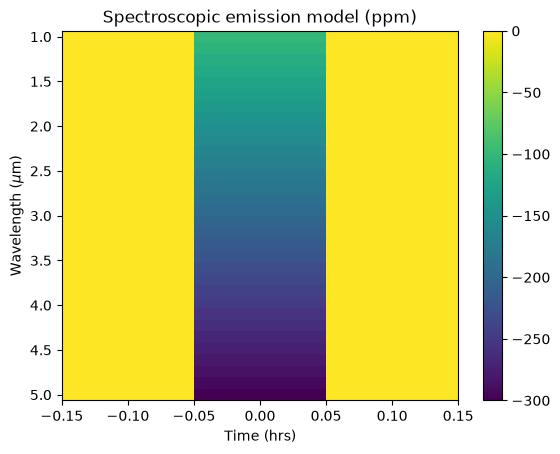

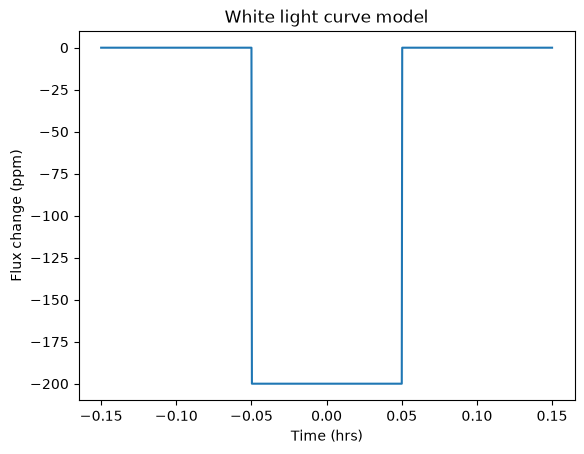

In [3]:
def eclipse_2D(p, X):
    x_t = X[1].copy()

    # Linear baseline
    flux = jnp.outer(p["Foot"][0], jnp.ones_like(x_t))
    flux += jnp.outer(p["Tgrad"][0], (x_t - x_t.mean()))

    # In transit if within half a duration either side of phase = 0
    half_duration = p["t_dur"] / 2.0
    time_from_transit = x_t - p["T0"]
    in_transit = (time_from_transit > -half_duration) * (time_from_transit < half_duration)
    in_transit = jnp.where(in_transit, 1., 0.)

    flux *= 1. - jnp.outer(p["fp_fs"], in_transit)

    return flux

# Build model with 32 wavelengths, 1000 time points
N_l = 32
N_t = 1000

x_l = np.linspace(1., 5., N_l)
x_t = np.linspace(-0.15, 0.15, N_t)
X = (x_l, x_t)

mfp = {
    "Foot":  np.ones(N_l),                      # Baseline offset (i.e. flux out-of-transit)
    "Tgrad": 0. * np.ones(N_l),                 # Slope in baseline
    "T0":    0.,                                # Central eclipse time
    "t_dur": 0.1,                               # Eclipse duration in hours
    "fp_fs": np.linspace(100e-6, 300e-6, N_l),  # Planet-to-star flux ratio
}

# Model is in the correct mf(p, X, *mf_args, **mf_kwargs) format luas will use
M = eclipse_2D(mfp, X)

plt.title("Spectroscopic emission model (ppm)")
plt.pcolormesh(x_t, x_l, 1e6 * (M - 1.))
plt.gca().yaxis.set_inverted(True)
plt.colorbar()
plt.xlabel("Time (hrs)")
plt.ylabel(r"Wavelength ($\mu$m)")
plt.show()

plt.title("White light curve model")
plt.plot(x_t, 1e6 * (M.mean(0) - 1))
plt.ylabel("Flux change (ppm)")
plt.xlabel("Time (hrs)")
plt.show()

Now that we have our mean function created, it's time to start building a 2D kernel function. For this example, suppose we have white noise which varies in amplitude over different wavelengths, but with a constant amplitude in time. We also have some measurement covariance which could arise from some detector effect, i.e. each spectrum has some correlated noise draw added to it which is independent for each integration, such as due to 1/f readout noise, which we model here simply as an exponential kernel in wavelength.

$$
\begin{equation}
k(\lambda, \lambda', t, t') = \left[\sigma^2(\lambda)\delta_{\lambda\lambda'} + h^2_\textrm{readout}\exp\left(-\frac{|\lambda - \lambda'|}{l_\textrm{readout}}\right)\right]\delta_{t t'}\nonumber
\end{equation}
$$

This kernel can be written as a single wavelength kernel function times a single time kernel function:
$$
\begin{aligned}
    s_\lambda(\lambda, \lambda') &= \sigma^2(\lambda)\delta_{\lambda\lambda'} + h^2_\textrm{readout}\exp\left(-\frac{|\lambda - \lambda'|}{l_\textrm{readout}}\right)\\
    s_t(t, t') &= \delta_{t t'}
\end{aligned}
$$

In this scenario, we can describe the full covariance matrix created as a single Kronecker product of a wavelength covariance matrix and a time covariance matrix:
$$
\begin{aligned}
    (\Sigma_\lambda)_{ij} &= s_\lambda(\lambda_i, \lambda_j)\\
    (\Sigma_t)_{ij} &= s_t(t_i, t_j)\\
    \mathbf{K} &= \Sigma_\lambda \otimes \Sigma_t
\end{aligned}
$$
This mathematical structure will be exploited by the ``SeparableKernel`` GP optimisation as implemented by ``luas``. This optimisation is originally from Saatchi (2011), but has been adapted to work with tinygp and quasiseparable kernels for linear runtime scaling!

Let's start with building these kernels individually. ``luas`` has a simple kernel building interface where kernels can be added together and multiplied easily


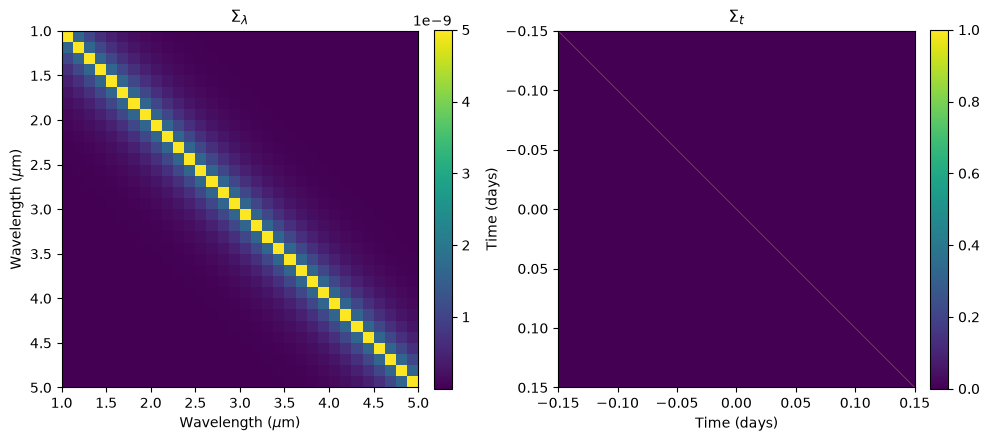

In [4]:
p = {
    "log_sigma":np.log(50e-6)*np.ones(N_l),
    "sigma_t":np.linspace(0.5, 2., N_t),

    "log_h_readout":np.log(50e-6),
    "log_l_readout":np.log(0.3),
}

# We use the Noise kernel to describe white noise, so it goes to zero when calculating the GP mean
# Currently takes the standard deviation of the white noise (might change to variance in final released code)
s_l = luas.kernels.Noise(jnp.exp(p["log_sigma"]))

# Add our readout noise term, note we can just multiply scalars by kernels too
# Can swap this to luas.kernels.quasisep.Exp to exploit tinygp optimisations
s_l += jnp.exp(2*p["log_h_readout"]) * luas.kernels.Exp(jnp.exp(p["log_l_readout"]))

# If you would like to build the covariance matrix, give it the regression vectors x and x' to build it
# matching the convention in tinygp
Sigma_l = s_l(x_l, x_l)

# The KroneckerDelta kernel is the same as the Noise kernel but it won't go to zero for the GP mean calculation
# It should be used if modelling a kernel term which is uncorrelated in one dimenion,
# but is being multiplied by any kernel terms which are correlated in another dimension
s_t = luas.kernels.KroneckerDelta(1.)
Sigma_t = s_t(x_t, x_t)

# You can also give a vector of standard deviation over time if desired,
# Remember that these values get multiplied by the wavelength covariance matrix
# s_t = luas.kernels.KroneckerDelta(p["sigma_t"])
# Sigma_t = s_t(x_t, x_t)

# Plot these covariance matrices
fig, ax = plt.subplots(1, 2, figsize = (10, 5))
ax[0].set_title(r"$\Sigma_\lambda$")
im0 = ax[0].imshow(Sigma_l, extent = [x_l[0], x_l[-1], x_l[-1], x_l[0]])
ax[0].set_ylabel(r"Wavelength ($\mu$m)")
ax[0].set_xlabel(r"Wavelength ($\mu$m)")
plt.colorbar(im0, ax = ax[0], fraction=0.046, pad=0.04)

ax[1].set_title(r"$\Sigma_t$")
im1 = ax[1].imshow(Sigma_t, extent = [x_t[0], x_t[-1], x_t[-1], x_t[0]])
ax[1].set_ylabel("Time (days)")
ax[1].set_xlabel("Time (days)")
plt.colorbar(im1, ax = ax[1], fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()


Now that we see how we can create these individual kernel functions, let's create a 2D kernel function which multiplies these together. We will create our kernel from before within the ``kf(p, X)`` function, as this is the preferred interface for inputting a kernel function to the ``luas.GP`` interface. Here are our kernels to implement:
$$
\begin{aligned}
    s_\lambda(\lambda, \lambda') &= \sigma^2(\lambda)\delta_{\lambda\lambda'} + h^2_\textrm{readout}\exp\left(-\frac{|\lambda - \lambda'|}{l_\textrm{readout}}\right)\\
    s_t(t, t') &= \delta_{t t'}
\end{aligned}
$$

Using: SeparableKernel
Starting log posterior value: 271786.6886261156


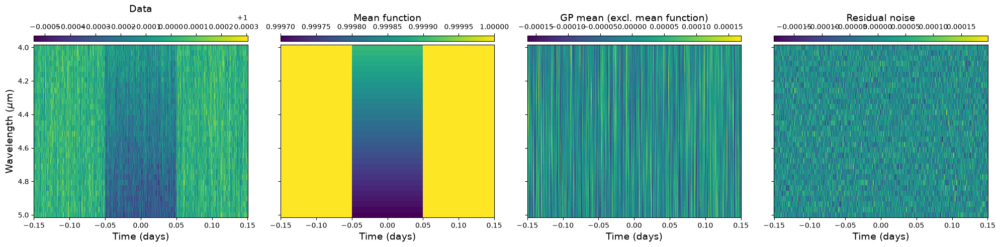

In [5]:
# Input kernel function also starts with the same two arguments
#   p: a PyTree of parameters
#   X: the regression vectors as a tuple of arrays in each dimension
def kf_readout(p, X):
    # We use the Noise kernel to describe actual white noise, this term will go to zero when visualising the GP mean
    s_l = luas.kernels.Noise(jnp.exp(p["log_sigma"]))

    # Add our readout noise term (can swap to luas.kernels.quasisep.Exp for faster runtimes and still be exact)
    s_l += jnp.exp(2*p["log_h_readout"]) * luas.kernels.Exp(jnp.exp(p["log_l_readout"]))

    # Our KroneckerDelta kernel for the time kernel, this describes time-independence
    # Try seeing what happens if this is changed to luas.kernels.Noise instead,
    # the log-likelihood and inference will not be affected, but the GP mean goes to zero as it the GP mean doesn't fit Noise
    # It can also take a vector of amplitudes if desired
    s_t = luas.kernels.KroneckerDelta(1.)

    # For multidim kernels we return a tuple containing the wavelength kernel and time kernels
    # The first kernel term will use the regression vector(s) stored in X[0] to build covariance matrices
    # Similarly the second kernel term uses X[1] and so on,
    # we can also do 3+ dimensions for the SeparableKernel if desired!
    return (s_l, s_t)

# Feel free to play around with the dataset size to see runtime difference
N_l = 32    # Number of wavelengths
N_t = 1024  # Number of timepoints

x_l = np.linspace(4., 5., N_l)
x_t = jnp.linspace(-0.15, 0.15, N_t)
X = (x_l, x_t)

# Mean function parameters
p_init = deepcopy(mfp)
p_init["fp_fs"] = np.linspace(100e-6, 300e-6, N_l)
p_init["Foot"] = 1.*np.ones(N_l)
p_init["Tgrad"] = 0.*np.ones(N_l)

# Define our hyperparameters
hp = {
    "log_sigma":np.log(50e-6)*np.ones(N_l),

    "log_h_readout":np.log(50e-6),
    "log_l_readout":np.log(0.3),
}
p_init = deepcopy(mfp)
p_init.update(hp)

# Define our GP model, also starting with p, X
gp = luas.GP(p_init, X, mf = eclipse_2D, kf = kf_readout)

# Ensure a consistent noise draw
np.random.seed(42)

# Sample from the GP prior, including both the mean function and a draw from the covariance matrix
# Useful for simulating data and also visualising what the GP model looks like at the starting parameter values
Y = gp.sample(p_init, add_mf = True)

print("Starting log posterior value:", gp.logP(p_init, Y))

# Visualise the simulated data and the initial GP fit to the data (in this case the GP fit has the optimal simulated parameters)
gp_mean, mf_model = gp.plot(p_init, Y, axes_labels = [r"Wavelength ($\mu$m)", r"Time (days)"], return_fit = True)
plt.show()

We can see the GP mean contains vertical streaks of correlated noise, characteristic of certain readout noise such as 1/f noise in JWST/NIRCam (e.g. see [Ahrer et al. 2023](https://www.nature.com/articles/s41586-022-05590-4))

If we look at the white light curve we will see that the readout noise makes it substantially noiser (as it bins down slowly in wavelength)

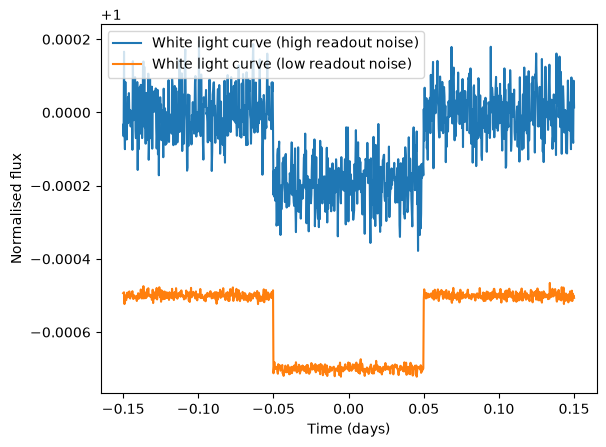

In [6]:
# Copy the original parameters and set high readout noise
p_readout = deepcopy(p_init)
p_readout["log_h_readout"] = np.log(100e-6)
Y_readout = gp.sample(p_readout, add_mf = True)
plt.plot(x_t, Y_readout.mean(0), label = "White light curve (high readout noise)")

# Copy the same parameters but lower readout noise to 1e-9
p_clean = deepcopy(p_init)
p_clean["log_h_readout"] = np.log(1e-9)

Y_clean = gp.sample(p_clean, add_mf = True)
plt.plot(x_t, Y_clean.mean(0) - 500e-6, label = "White light curve (low readout noise)")

plt.xlabel("Time (days)")
plt.ylabel("Normalised flux")
plt.legend()
plt.show()

We can always visualise all covariance matrices created by the `luas.GP` object using the ``plot_cov_mat`` method, which will create a plot similar to what we made before

Note: For lots of time points pcolormesh can render weirdly which you might see in the time covariance matrix

Warning: Don't run with 10,000s of points in a single dimension, you can run out of RAM very quickly even just building the individual covariance matrices!

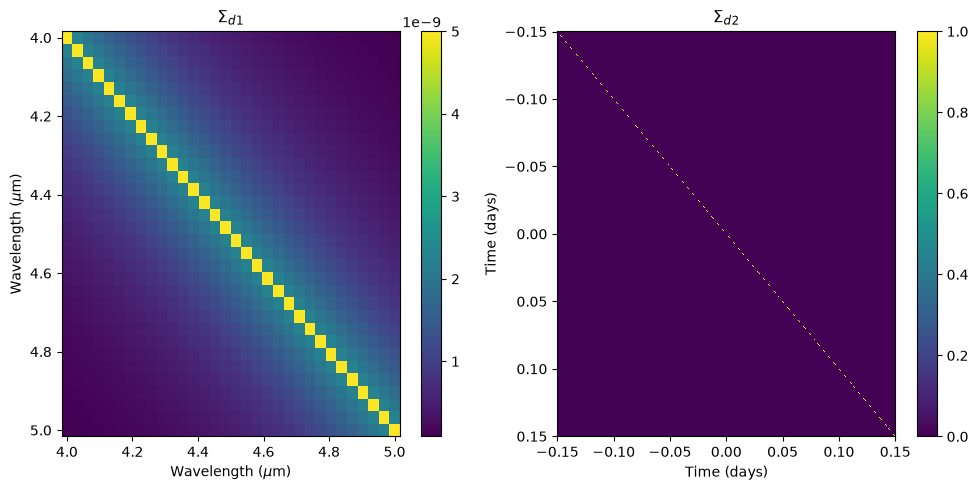

In [7]:
gp.plot_cov_mat(p_init, axes_labels = [r"Wavelength ($\mu$m)", r"Time (days)"])

Since an exponential kernel plus diagonal noise can be modelled as a quasiseparable kernel, we can swap out our base kernels from ``luas.kernels`` with ``luas.kernels.quasisep`` which can decompose the individual wavelength and time covariance matrices much faster for larger datasets. The ``luas.kernels.quasisep`` submodule is a backend for ``tinygp``, which implements linear time algorithms to decompose quasiseparable kernels, e.g. including the exponential kernel, Matérn-3/2, and Matérn-5/2 kernels exactly. The ``Noise`` and ``KroneckerDelta`` kernels are also valid quasisep kernels and it's good practice to change them to ``luas.kernels.quasisep`` if adding them to other quasisep kernels. Check out the kernels implemented in ``luas.kernels.quasisep`` to see all the kernels that can be used.

We can also see the cost of evaluating the kernel without any 2D optimisation at all, by setting ``use_kernel=luas.GeneralKernel`` to build the full covariance matrix of the data and decompose using a general Cholesky decomposition. Be very careful using this however as it needs to build a $(N_l N_t, N_l N_t)$ covariance matrix, which will very quickly run out of memory after $>10,000$ total points

In [10]:
# Input kernel function also starts with the same two arguments
#   p: a PyTree of parameters
#   X: the regression vectors as a tuple of arrays in each dimension
def kf_readout_quasisep(p, X):

    # We can swap to quasisep kernels in this case which can scale much faster!
    s_l = luas.kernels.quasisep.Noise(jnp.exp(p["log_sigma"]))
    s_l += jnp.exp(2*p["log_h_readout"]) * luas.kernels.quasisep.Exp(jnp.exp(p["log_l_readout"]))

    s_t = luas.kernels.quasisep.KroneckerDelta(1.)

    return (s_l, s_t)

# Feel free to play around with the dataset size to see runtime difference
N_l = 32    # Number of wavelengths
N_t = 100  # Number of timepoints

x_l = np.linspace(4., 5., N_l)
x_t = jnp.linspace(-0.15, 0.15, N_t)
X = (x_l, x_t)

p_init = deepcopy(mfp)
p_init["fp_fs"] = np.linspace(100e-6, 300e-6, N_l)
p_init["Foot"] = 1.*np.ones(N_l)
p_init["Tgrad"] = 0.*np.ones(N_l)

# Define our hyperparameters
hp = {
    "log_sigma":np.log(50e-6)*np.ones(N_l),

    "log_h_readout":np.log(50e-6),
    "log_l_readout":np.log(0.3),
}
p_init.update(hp)

gp_slow = luas.GP(p_init, X, kf = kf_readout, mf = eclipse_2D)
gp_fast = luas.GP(p_init, X, kf = kf_readout_quasisep, mf = eclipse_2D)

# Ensure a consistent noise draw
np.random.seed(42)

# Sample from the GP prior, including both the mean function and a draw from the covariance matrix
Y = gp_fast.sample(p_init, add_mf = True)


if N_l * N_t < 16000:
    # luas will identify an exact optimisation to use on initialisation,
    # but we are free to specify any valid optimisation or lack thereof we wish
    # To force luas to not use any 2D optimisation and build the full covariance matrix
    # set use_kernel = luas.GeneralKernel, useful for testing purposes
    gp_no_opt = luas.GP(p_init, X, use_kernel = luas.GeneralKernel,
                        kf = kf_readout, mf = eclipse_2D,
                        )

    logP_no_opt = gp_no_opt.logP(p_init, Y).block_until_ready()
    print(f"Log-posterior without any 2D GP optimisation: \t{logP_no_opt}")
    print("\nRuntime for log-posterior calculation without any optimisations:")
    %timeit gp_no_opt.logP(p_init, Y).block_until_ready()

logP_slow = gp_slow.logP(p_init, Y).block_until_ready()
logP_fast = gp_fast.logP(p_init, Y).block_until_ready()

print(f"\nLog-posterior with SeparableKernel and without quasisep kernels: \t{logP_slow}")
print(f"Log-posterior with SeparableKernel and quasisep kernels: \t\t{logP_fast}")

print(f"\nRuntime for log-likelihood calculation with {gp_slow.opt_name} and base kernels:")
%timeit gp_slow.logP(p_init, Y).block_until_ready()

print(f"\nRuntime for log-likelihood calculation with {gp_fast.opt_name} and quasisep kernels:")
%timeit gp_fast.logP(p_init, Y).block_until_ready()

if N_l * N_t < 16000:
    print("Try increasing the number of wavelengths to see the improved scaling from quasisep kernels")

Using: SeparableKernel
Using: SeparableKernel
Using: GeneralKernel
Log-posterior without any 2D GP optimisation: 	26578.150081016523

Runtime for log-posterior calculation without any optimisations:
62.3 ms ± 1.76 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)

Log-posterior with SeparableKernel and without quasisep kernels: 	26578.15008101653
Log-posterior with SeparableKernel and quasisep kernels: 		26578.15008101653

Runtime for log-likelihood calculation with SeparableKernel and base kernels:
46.2 μs ± 2.49 μs per loop (mean ± std. dev. of 7 runs, 10,000 loops each)

Runtime for log-likelihood calculation with SeparableKernel and quasisep kernels:
49.8 μs ± 823 ns per loop (mean ± std. dev. of 7 runs, 10,000 loops each)
Try increasing the number of wavelengths to see the improved scaling from quasisep kernels


Now that we have measurement covariance covered, let's add in some noise which is correlated in time, but constant in wavelength (i.e. common-mode systematics). For correlated noise, let's choose a Matérn-3/2 kernel in time:
$$
\begin{equation}
k(\lambda, \lambda', t, t') = \left[\sigma^2(\lambda)\delta_{\lambda\lambda'} + h^2_\textrm{readout}\exp\left(-\frac{|\lambda - \lambda'|}{l_\textrm{readout}}\right)\right]\delta_{tt'} + h^2 * \text{Matérn}_{3/2}\left(-\frac{|t - t'|}{l_{t_1}}\right)\nonumber
\end{equation}
$$

This kernel contains a correlated noise component with height scale $h$ and length scale in time $l_t$. There is also a white noise term with different white noise amplitudes at different wavelengths, and our measurement covariance from earlier.

We can write this kernel as separate wavelength and time kernel functions multiplied together, i.e.
$$
\begin{equation}
k(\lambda, \lambda', t, t') = s_l(\lambda, \lambda')s_t(t, t') + k_l(\lambda, \lambda')k_t(t, t')\nonumber
\end{equation}
$$
Where we have
$$
\begin{aligned}
    s_l(\lambda, \lambda') &= \sigma^2(\lambda)\delta_{\lambda\lambda'} + h^2_\textrm{readout}\exp\left(-\frac{|\lambda - \lambda'|}{l_\textrm{readout}}\right) &\hspace{2em} s_t(t, t') &= \delta_{t t'} \\
    k_l(\lambda, \lambda') &= h^2 &\hspace{2em} k_{t_1}(t, t') &= \text{Matérn}_{3/2}\left(-\frac{|t - t'|}{l_{t_1}}\right)\nonumber
\end{aligned}
$$
Which build two Kronecker products
$$
\begin{equation}
\mathbf{K} = \mathbf{\Sigma}_\lambda \otimes \mathbf{\Sigma}_t + \mathbf{K}_\lambda \otimes \mathbf{K}_t\nonumber
\end{equation}
$$
WARNING: For numerical stability reasons, it's important that $\mathbf{\Sigma}_l$ and $\mathbf{\Sigma}_t$ are positive definite and well-conditioned (i.e. can be stably inverted), and they must correspond to the first tuple returned by the kernel function, so that ``luas`` knows which ones they are. Matrices which contain positive values added along the diagonal should be well-conditioned as this "regularises" the matrices. Even though the constant kernel in $k_l$ will not build an invertible matrix, and $\mathbf{K}_\lambda$ and $\mathbf{K}_t$ will not be well-conditioned, this is fine because they are added to $\mathbf{\Sigma}_l$ and $\mathbf{\Sigma}_t$ which are invertible.

Using: LuasLasrachKernel/MultiLowRankKernel

Starting log posterior value: 254093.5283386712


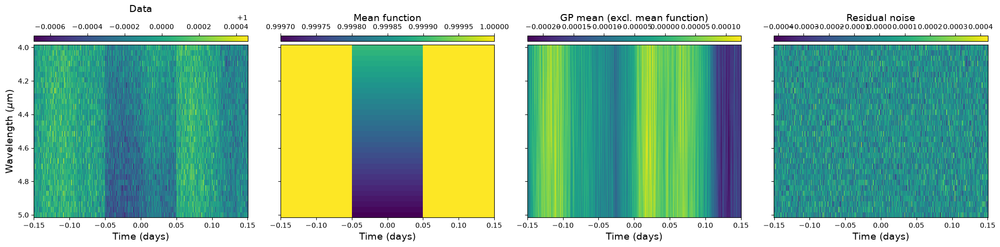

In [11]:
def kf_with_timecorr(p, X):
    # Our kernel with measurement covariance from before
    s_l = luas.kernels.Noise(jnp.exp(p["log_sigma"]))
    s_l += jnp.exp(2*p["log_h_readout"]) * luas.kernels.Exp(jnp.exp(p["log_l_readout"]))
    s_t = luas.kernels.KroneckerDelta()

    # Our kernel describing time-correlated noise which is constant in wavelength
    # Give in terms of constant standard deviation (cov mat will equal this squared)
    k_l = luas.kernels.Constant(jnp.exp(p["log_h"]))
    k_t = luas.kernels.Matern32(jnp.exp(p["log_l_t"]))

    # Warning: Make sure to include the terms s_l, s_t first as they build invertible covariance matrices
    # We simply include our new Kronecker product as a second returned tuple
    return (s_l, s_t), (k_l, k_t)

# Feel free to play around with the dataset size to see runtime difference
N_l = 32    # Number of wavelengths
N_t = 1024  # Number of timepoints

x_l = np.linspace(4., 5., N_l)
x_t = jnp.linspace(-0.15, 0.15, N_t)
X = (x_l, x_t)

p_init = deepcopy(mfp)
p_init["fp_fs"] = np.linspace(100e-6, 300e-6, N_l)
p_init["Foot"] = 1.*np.ones(N_l)
p_init["Tgrad"] = 0.*np.ones(N_l)

hp = {
    "log_sigma":np.log(100e-6)*np.ones(N_l),

    "log_h_readout":np.log(30e-6),
    "log_l_readout":np.log(0.3),

    "log_h":np.log(80e-6),
    "log_l_t":np.log(0.04),
}
p_init.update(hp)

gp = luas.GP(p_init, X, mf = eclipse_2D, kf = kf_with_timecorr)

# Ensure a consistent noise draw
np.random.seed(42)

# sample from the GP prior again
Y = gp.sample(p_init, add_mf = True)

print("\nStarting log posterior value:", gp.logP(p_init, Y))

# Visualise the simulated data and the initial GP fit to the data (in this case the GP fit has the optimal simulated parameters)
gp_mean, mf_model = gp.plot(p_init, Y, axes_labels = [r"Wavelength ($\mu$m)", r"Time (days)"], return_fit = True)
plt.show()


Our white light curve now has obvious time-correlated noise on top of the increased scatter from readout noise

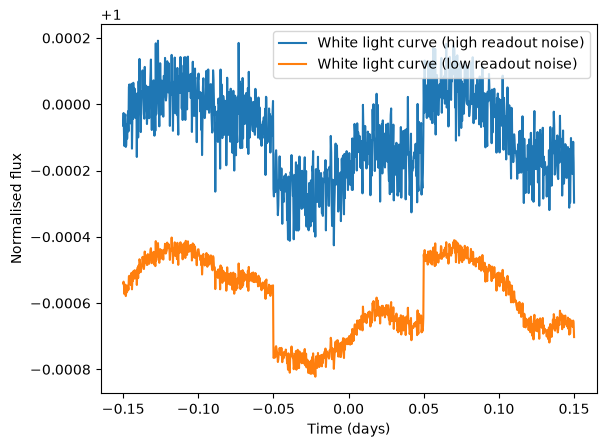

In [12]:
seed = 42

# Copy the original parameters and set high readout noise
p_readout = deepcopy(p_init)
p_readout["log_h_readout"] = np.log(100e-6)

np.random.seed(seed)
Y_readout = gp.sample(p_readout, add_mf = True)
plt.plot(x_t, Y_readout.mean(0), label = "White light curve (high readout noise)")

# Copy the same parameters but lower readout noise to 1e-9
p_clean = deepcopy(p_init)
p_clean["log_h_readout"] = np.log(1e-9)

np.random.seed(seed)
Y_clean = gp.sample(p_clean, add_mf = True)
plt.plot(x_t, Y_clean.mean(0) - 500e-6, label = "White light curve (low readout noise)")

plt.xlabel("Time (days)")
plt.ylabel("Normalised flux")
plt.legend()
plt.show()

In the case of a covariance matrix built as a sum of two Kronecker products, we have two different GP optimisations we can use. The first is implemented as the ``LuasKernel``, already included in the original ``luas`` package, which implements the method from Rakitsch et al. (2013). The second is the ``LuasLasrachKernel``* which can utilise a fast GP optimisation in one of the dimensions, including with quasiseparable kernels. For this to work, all kernel functions in that dimension must be implemented within the same kernel optimisation.

The ideal setup for the ``LuasLasrachKernel`` - assuming we have more time points than wavelengths - is to have $s_\lambda$, $s_t$ and $k_t$ to all build either diagonal matrices (only ``Noise`` and ``KroneckerDelta``) or quasiseparable matrices (created by ``luas.kernels.quasisep``). We also get a big speed-up if $k_\lambda$ is a low-rank matrix from ``luas.kernels.lowrank``:

$$
\begin{equation}
k(\lambda, \lambda', t, t') = s_\mathrm{\lambda; quasi}(\lambda, \lambda')s_\mathrm{t; quasi}(t, t') + k_\mathrm{\lambda; lowrank}(\lambda, \lambda')k_\mathrm{t; quasi}(t, t')
\end{equation}
$$

Our constant kernel is a valid ``luas.kernels.lowrank`` kernel as it builds a covariance matrix with only one non-zero eigenvalue (a rank-1 matrix).

*'luas' is the Irish word for speed (pronounced like Lewis), 'luas lasrach' is the Irish for 'lightning speed' (pronounced like Lewis loss-rock)

Using: LuasKernel
Using: LuasLasrachKernel/MultiLowRankKernel
Using: LuasLasrachKernel/MultiLowRankKernel
Log-likelihood with LuasKernel: 	26578.15008101653
Log-likelihood with LuasLasrachKernel: 	26578.15008101653


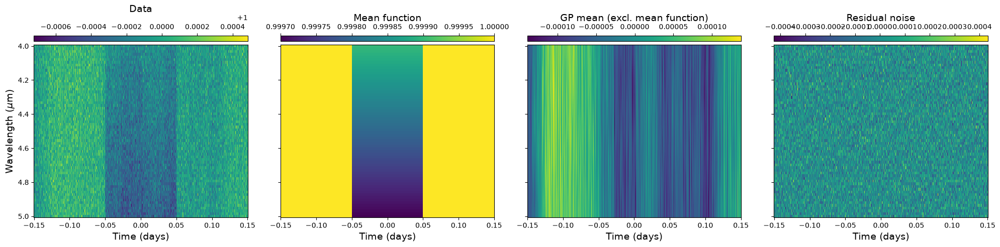


Runtime for log-likelihood calculation with LuasKernel: 
19.2 ms ± 488 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)

Runtime for log-likelihood calculation with LuasLasrachKernel:
113 μs ± 1.54 μs per loop (mean ± std. dev. of 7 runs, 10,000 loops each)

Runtime for log-likelihood calculation with LuasLasrachKernel without mean function calculation:
95.8 μs ± 2.53 μs per loop (mean ± std. dev. of 7 runs, 10,000 loops each)


In [13]:
def kf_slow(p, X):
    # Same kernel as before
    s_l = luas.kernels.Noise(jnp.exp(p["log_sigma"]))
    s_l += jnp.exp(2*p["log_h_readout"]) * luas.kernels.Exp(jnp.exp(p["log_l_readout"]))
    s_t = luas.kernels.KroneckerDelta()

    k_l = luas.kernels.Constant(jnp.exp(p["log_h"]))
    k_t = luas.kernels.Matern32(jnp.exp(p["log_l_t"]))

    return (s_l, s_t), (k_l, k_t)

def kf_fast(p, X):
    # Our kernel with measurement covariance from before
    s_l = luas.kernels.quasisep.Noise(jnp.exp(p["log_sigma"]))
    s_l += jnp.exp(2*p["log_h_readout"]) * luas.kernels.quasisep.Exp(jnp.exp(p["log_l_readout"]))
    s_t = luas.kernels.quasisep.KroneckerDelta()

    # Our kernel describing time-correlated noise which is constant in wavelength
    k_l = luas.kernels.lowrank.Constant(jnp.exp(p["log_h"]))
    k_t = luas.kernels.quasisep.Matern32(jnp.exp(p["log_l_t"]))

    # Warning: Make sure to include the terms s_l, s_t first as they build invertible covariance matrices which luas will use
    # We simply include our new Kronecker product as a second tuple returned
    return (s_l, s_t), (k_l, k_t)


# Feel free to play around with the dataset size to see runtime difference
N_l = 64    # Number of wavelengths
N_t = 512  # Number of timepoints

x_l = np.linspace(4., 5., N_l)
x_t = jnp.linspace(-0.15, 0.15, N_t)
X = (x_l, x_t)

p_init = deepcopy(mfp)
p_init["fp_fs"] = np.linspace(100e-6, 300e-6, N_l)
p_init["Foot"] = 1.*np.ones(N_l)
p_init["Tgrad"] = 0.*np.ones(N_l)

hp = {
    "log_sigma":np.log(100e-6)*np.ones(N_l),

    "log_h_readout":np.log(30e-6),
    "log_l_readout":np.log(0.3),

    "log_h":np.log(80e-6),
    "log_l_t":np.log(0.04),
}
p_init.update(hp)

# luas will identify fast, exact optimisations to use on initialisation, but we are free to specify any valid one we wish
# Here we will force it to use LuasKernel, it will otherwise use LuasLasrachKernel/MultiLowRankKernel which we will explain later
gp_slow = luas.GP(p_init, X, use_kernel = luas.LuasKernel, kf = kf_slow, mf = eclipse_2D)

# This should default to "LuasLasrachKernel/MultiLowRankKernel" if use_kernel is not specified
gp_fast = luas.GP(p_init, X, kf = kf_fast, mf = eclipse_2D, verbose = True)

# Create a GP object which doesn't generate eclipse light curves for benchmarking purposes
gp_fast_no_mf = luas.GP(p_init, X, kf = kf_fast)

# Ensure a consistent noise draw
np.random.seed(42)

# sample from the GP prior again
Y = gp_fast.sample(p_init, add_mf = True)

print(f"Log-likelihood with LuasKernel: \t{logP_slow}\nLog-likelihood with LuasLasrachKernel: \t{logP_fast}")

# Visualise the simulated data and the initial GP fit to the data (in this case the GP fit has the optimal simulated parameters)
gp_mean, mf_model = gp_fast.plot(p_init, Y, axes_labels = [r"Wavelength ($\mu$m)", r"Time (days)"], return_fit = True)
plt.show()

logP_slow = gp_slow.logL(p_init, Y).block_until_ready()
logP_fast = gp_fast.logL(p_init, Y).block_until_ready()

print("\nRuntime for log-likelihood calculation with LuasKernel: ")
%timeit gp_slow.logL(p_init, Y).block_until_ready()

print("\nRuntime for log-likelihood calculation with LuasLasrachKernel:")
%timeit gp_fast.logL(p_init, Y).block_until_ready()

print("\nRuntime for log-likelihood calculation with LuasLasrachKernel without mean function calculation:")
gp_fast_no_mf.logL(p_init, Y).block_until_ready()
%timeit gp_fast_no_mf.logL(p_init, Y).block_until_ready()


As you can see, the ``LuasLasrachKernel`` is extremely fast, to the point that the simple eclipse model becomes a non-negligble part of the runtime (and transit modelling with limb-darkening, etc. can actually become the bottleneck). Part of this huge speed-up is the use of a low-rank kernel in $k_\lambda$, let's swap it to a full-rank kernel like the Matérn-5/2 kernel. We'll give it a short wavelength length scale to simulate systematics that might be close to independent for each wavelength.

$$
\begin{equation}
k(\lambda, \lambda', t, t') = \left[\sigma^2(\lambda)\delta_{\lambda\lambda'} + h^2_\textrm{readout}\exp\left(-\frac{|\lambda - \lambda'|}{l_\textrm{readout}}\right)\right]\delta_{tt'} + h^2 * \text{Matérn}_{3/2}\left(-\frac{|\lambda - \lambda'|}{l_\lambda}\right)\text{Matérn}_{5/2}\left(-\frac{|t - t'|}{l_{t}}\right)
\end{equation}
$$

Where we have
$$
\begin{aligned}
    s_l(\lambda, \lambda') &= \sigma^2(\lambda)\delta_{\lambda\lambda'} + h^2_\textrm{readout}\exp\left(-\frac{|\lambda - \lambda'|}{l_\textrm{readout}}\right) &\hspace{2em} s_t(t, t') &= \delta_{t t'} \\
    k_l(\lambda, \lambda') &= h^2 * \text{Matérn}_{5/2}\left(-\frac{|\lambda - \lambda'|}{l_\lambda}\right) &\hspace{2em} k_{t_1}(t, t') &= \text{Matérn}_{3/2}\left(-\frac{|t - t'|}{l_{t}}\right)
\end{aligned}
$$

In contrast to $k_t$, setting $k_\lambda$ to use ``luas.kernels.quasisep`` won't actually result in a speed-up, even though Matérn-5/2 is a valid quasiseparable kernel. This is because an eigendecomposition of the $\mathbf{K}_\lambda$ matrix is required for both ``LuasKernel`` and ``LuasLasrachKernel``, which doesn't have a known optimisation for quasiseparable kernels

Using: LuasKernel
Using: LuasLasrachKernel
Using: LuasLasrachKernel
Log-likelihood with LuasKernel: 	253726.443115117
Log-likelihood with LuasLasrachKernel: 	253726.44311511703


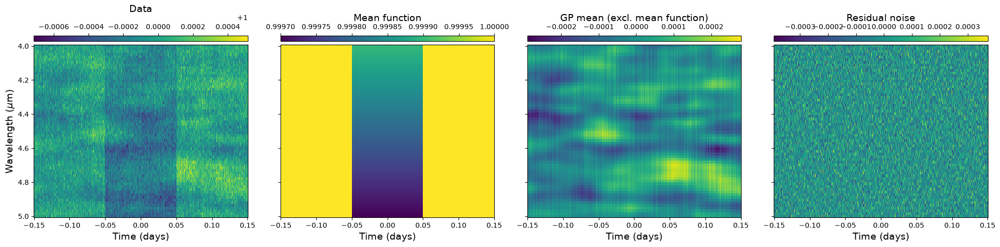


Runtime for log-likelihood calculation with LuasKernel:
19 ms ± 253 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)

Runtime for log-likelihood calculation with LuasLasrachKernel:
1.43 ms ± 14.4 μs per loop (mean ± std. dev. of 7 runs, 1,000 loops each)


In [14]:
# We implement each of these kernel functions below using the luas.kernels module

# Input kernel function also takes a PyTree of parameters and the regression vectors as a tuple of arrays in each dimension
# Order of kernels in each dimension should be in same order as the regression vectors in the tuple X
def kf_slow(p, X):
    # Same kernel as before
    s_l = luas.kernels.Noise(jnp.exp(p["log_sigma"]))
    s_l += jnp.exp(2*p["log_h_readout"]) * luas.kernels.Exp(jnp.exp(p["log_l_readout"]))
    s_t = luas.kernels.KroneckerDelta()

    k_l = jnp.exp(2*p["log_h"]) * luas.kernels.Matern52(jnp.exp(p["log_l_l"]))
    k_t = luas.kernels.Matern32(jnp.exp(p["log_l_t"]))

    return (s_l, s_t), (k_l, k_t)

def kf_fast(p, X):
    # Our kernel with measurement covariance from before
    s_l = luas.kernels.quasisep.Noise(jnp.exp(p["log_sigma"]))
    s_l += jnp.exp(2*p["log_h_readout"]) * luas.kernels.quasisep.Exp(jnp.exp(p["log_l_readout"]))
    s_t = luas.kernels.quasisep.KroneckerDelta()

    # Our kernel describing time-correlated noise which is constant in wavelength
    k_l = jnp.exp(2*p["log_h"]) * luas.kernels.Matern52(jnp.exp(p["log_l_l"]))
    k_t = luas.kernels.quasisep.Matern32(jnp.exp(p["log_l_t"]))

    # Warning: Make sure to include the terms s_l, s_t first as they build invertible covariance matrices which luas will use
    # We simply include our new Kronecker product as a second tuple returned
    return (s_l, s_t), (k_l, k_t)


# Feel free to play around with the dataset size to see runtime difference
N_l = 64    # Number of wavelengths
N_t = 512  # Number of timepoints

x_l = np.linspace(4., 5., N_l)
x_t = jnp.linspace(-0.15, 0.15, N_t)
X = (x_l, x_t)

p_init = deepcopy(mfp)
p_init["fp_fs"] = np.linspace(100e-6, 300e-6, N_l)
p_init["Foot"] = 1.*np.ones(N_l)
p_init["Tgrad"] = 0.*np.ones(N_l)

hp = {
    "log_sigma":np.log(100e-6)*np.ones(N_l),

    "log_h_readout":np.log(30e-6),
    "log_l_readout":np.log(0.3),

    "log_h":np.log(80e-6),
    "log_l_l":np.log(0.05),
    "log_l_t":np.log(0.04),
}
p_init.update(hp)

# luas will identify fast, exact optimisations to use on initialisation, but we are free to specify any valid one we wish
# Here we will force it to use LuasKernel, it will otherwise use MultiLowRankKernel which we will explain later
gp_slow = luas.GP(p_init, X, use_kernel = luas.LuasKernel, kf = kf_slow, mf = eclipse_2D)
gp_fast = luas.GP(p_init, X, kf = kf_fast, mf = eclipse_2D)
gp_fast_no_mf = luas.GP(p_init, X, kf = kf_fast)

# Ensure a consistent noise draw
np.random.seed(42)

# sample from the GP prior again
Y = gp_fast.sample(p_init, add_mf = True)

logL_slow = gp_slow.logL(p_init, Y).block_until_ready()
logL_fast = gp_fast.logL(p_init, Y).block_until_ready()

print(f"Log-likelihood with LuasKernel: \t{logL_slow}\nLog-likelihood with LuasLasrachKernel: \t{logL_fast}")

# Visualise the simulated data and the initial GP fit to the data (in this case the GP fit has the optimal simulated parameters)
gp_mean, mf_model = gp_fast.plot(p_init, Y, axes_labels = [r"Wavelength ($\mu$m)", r"Time (days)"], return_fit = True)
plt.show()

print("\nRuntime for log-likelihood calculation with LuasKernel:")
%timeit gp_slow.logL(p_init, Y).block_until_ready()

print("\nRuntime for log-likelihood calculation with LuasLasrachKernel:")
%timeit gp_fast.logL(p_init, Y).block_until_ready()


``LuasLasrachKernel`` is still much faster than ``LuasKernel`` here, but not having a low-rank kernel for $k_\lambda$ does significantly slow it down. Their scaling in this case is $\mathcal{O}(N_\lambda^3 + N_t^3 + N_\lambda N_t (N_\lambda + N_t))$ for the `LuasKernel` (regardless of quasiseparable kernels) and ~$\mathcal{O}(N_\lambda^3 + R_{K_\lambda} N_t J_{K_t}^2 + N_\lambda N_t J_{\Sigma_\lambda})$ for ``LuasLasrachKernel``, where $J_{\Sigma_\lambda}$ is the quasiseparable rank of $\mathbf{\Sigma}_\lambda$ and similarly for $\mathbf{K}_t$. $R_{K_\lambda}$ is the (eigen) rank of $\mathbf{K}_\lambda$ (i.e. number of non-zero eigenvalues).

We can also scale kernels if they have an amplitude that varies over their own domain, so a wavelength kernel that is larger at some wavelengths than others. We scale this with the `luas.kernels.lowrank.Amplitude` kernel, which takes a vector of amplitudes at each wavelength (be careful not to square it!). We can even scale quasiseparable kernels to vary their amplitude without increasing their quasiseparable rank. Let's do a wavelength-dependent amplitude for the previous model, which could be appropriate for systematics that might be much larger in certain wavelength regions. Our model is:
$$
\begin{equation}
k(\lambda, \lambda', t, t') = \left[\sigma^2(\lambda)\delta_{\lambda\lambda'} + h^2_\textrm{readout}\exp\left(-\frac{|\lambda - \lambda'|}{l_\textrm{readout}}\right)\right]\delta_{tt'} + \left[h(\lambda)h(\lambda') \text{Matérn}_{5/2}\left(-\frac{|\lambda - \lambda'|}{l_\lambda}\right)\right]\text{Matérn}_{3/2}\left(-\frac{|t - t'|}{l_{t}}\right)\nonumber
\end{equation}
$$

Where we have
$$
\begin{aligned}
    s_\lambda(\lambda, \lambda') &= \sigma^2(\lambda)\delta_{\lambda\lambda'} + h^2_\textrm{readout}\exp\left(-\frac{|\lambda - \lambda'|}{l_\textrm{readout}}\right) &\hspace{2em} s_t(t, t') &= \delta_{t t'} \\
    k_\lambda(\lambda, \lambda') &= h_\lambda(\lambda)h_\lambda(\lambda') \text{Matérn}_{5/2}\left(-\frac{|\lambda - \lambda'|}{l_\lambda}\right) &\hspace{2em} k_{t}(t, t') &= \text{Matérn}_{3/2}\left(-\frac{|t - t'|}{l_{t}}\right)
\end{aligned}
$$

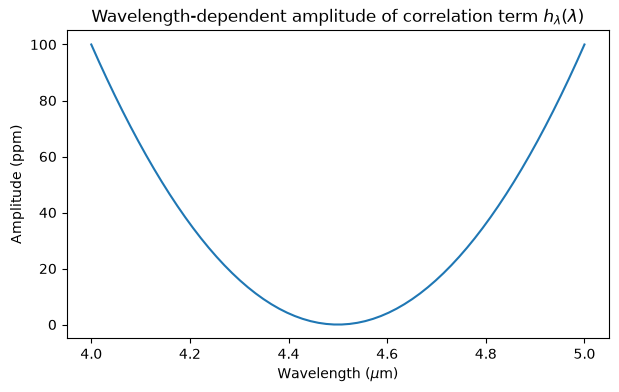

Using: LuasLasrachKernel
Starting log-posterior value: 508048.2242696452


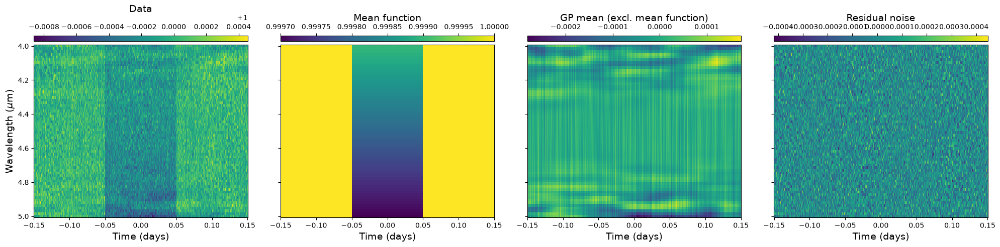

In [15]:
def kf_scaled2Dkernel(p, X):
    # Our kernel with measurement covariance from before
    s_l = luas.kernels.quasisep.Noise(jnp.exp(p["log_sigma"]))
    s_l += jnp.exp(2*p["log_h_readout"]) * luas.kernels.quasisep.Exp(jnp.exp(p["log_l_readout"]))
    s_t = luas.kernels.quasisep.KroneckerDelta()

    # Our kernel describing time-correlated noise which is constant in wavelength
    k_l = luas.kernels.lowrank.Amplitude(jnp.exp(p["log_h_l"])) * luas.kernels.Matern52(jnp.exp(p["log_l_l"]))
    k_t = luas.kernels.quasisep.Matern32(jnp.exp(p["log_l_t"]))

    # Warning: Make sure to include the terms s_l, s_t first as they build invertible covariance matrices which luas will use
    # We simply include our new Kronecker product as a second tuple returned
    return (s_l, s_t), (k_l, k_t)


# Feel free to play around with the dataset size to see runtime difference
N_l = 64    # Number of wavelengths
N_t = 1024  # Number of timepoints

x_l = np.linspace(4., 5., N_l)
x_t = jnp.linspace(-0.15, 0.15, N_t)
X = (x_l, x_t)

p_init = deepcopy(mfp)
p_init["fp_fs"] = np.linspace(100e-6, 300e-6, N_l)
p_init["Foot"] = 1.*np.ones(N_l)
p_init["Tgrad"] = 0.*np.ones(N_l)

h_l_vec = 400e-6 * (X[0] - X[0].mean())**2 * np.ones(N_l)
plt.figure(figsize = (7, 4))
plt.title(r"Wavelength-dependent amplitude of correlation term $h_\lambda(\lambda)$")
plt.plot(x_l, 1e6 * h_l_vec)
plt.xlabel(r"Wavelength ($\mu$m)")
plt.ylabel("Amplitude (ppm)")
plt.show()

hp = {
    "log_sigma":np.log(100e-6)*np.ones(N_l),

    "log_h_readout":np.log(30e-6),
    "log_l_readout":np.log(0.3),

    "log_h_l":np.log(h_l_vec),
    "log_l_l":np.log(0.03),
    "log_l_t":np.log(0.04),
}
p_init.update(hp)

gp = luas.GP(p_init, X, mf = eclipse_2D, kf = kf_scaled2Dkernel)

# Ensure a consistent noise draw
np.random.seed(42)

# sample from the GP prior again
Y = gp.sample(p_init, add_mf = True)

logP_val = gp.logP(p_init, Y)
print(f"Starting log-posterior value: {logP_val}")

# Visualise the simulated data and the initial GP fit to the data (in this case the GP fit has the optimal simulated parameters)
gp_mean, mf_model = gp.plot(p_init, Y, axes_labels = [r"Wavelength ($\mu$m)", r"Time (days)"], return_fit = True)
plt.show()


Since low-rank kernel terms can produce extremely optimised models, they are worth exploring in more detail. We can add arbitrary numbers of kernel terms when they are all low-rank in the same dimension using the ``MultiLowRankKernel`` optimisation. For just a single low-rank term such as the common-mode term from before, this kernel converges exactly to the ``LuasLasrachKernel``, but the ``MultiLowRankKernel`` optimisation extends this to multiple terms and can still make use of quasiseparable kernels along one of the dimensions. When we combine low-rank kernels with quasiseparable kernels we often get very optimised GP calculations. Mathematically, we are considering kernel functions of this form:
$$
\begin{equation}
    k(\lambda, \lambda', t, t') = s_{\lambda; \mathrm{quasi}}(\lambda, \lambda')s_\mathrm{t; quasi}(t, t') + \sum_{i=1}^{N_\alpha}\alpha_i(\lambda) \alpha_i(\lambda') k_\mathrm{t_i; quasi}(t, t') \nonumber
\end{equation}
$$
where $\alpha_i(\lambda)$ can be any function which is used to generate $N_\lambda$-long vectors $\boldsymbol{\alpha}_{\lambda_i}$, and the 'quasi' kernel terms can also be uncorrelated terms such as a Kronecker delta. Note that we don't require these terms to be quasiseparable at all, they could also consist of any `luas.kernels` term, but we can achieve linear scaling in the time dimension if they are. If $s_{\lambda}$ is quasiseparable we also get linear scaling in wavelength, but we maintain linear scaling in time even if it isn't quasiseparable.

Alternatively, you can also think of $\mathbf{\alpha}_i = \alpha_i(\lambda)$ as $N_\lambda$-long vectors of free parameters which build the covariance matrix:
$$
\begin{equation}
\mathbf{K} = \mathbf{\Sigma}_{\lambda}  \otimes \mathbf{\Sigma}_{t} + \sum_{i=1}^{N_\alpha} \left(\boldsymbol{\alpha}_{\lambda_i} \boldsymbol{\alpha}_{\lambda_i}^T \otimes \mathbf{K}_{t; i}\right) \nonumber
\end{equation}
$$
For our example, let's take our constant kernel from before, which is equivalent to a constant vector $\mathbf{\alpha}_{\lambda_1} = h * \mathbf{1}$, and let's suppose our tenth light curve also shows significant systematics that we want an extra term to model, this time using a squared-exponential kernel. To keep the optimisation efficient using quasiseparable kernels in time, we can use the ``luas.kernels.quasisep.SquaredExpApprox`` kernel, which produces close approximations to the shape of the true squared exponential kernel (the log-likelihood calculation itself is still exact for the kernel shape it uses, see the next cell). We will also keep our measurement covariance from earlier, resulting in a kernel of:
$$
\begin{aligned}
    s_\lambda(\lambda, \lambda') &= \sigma^2(\lambda)\delta_{\lambda\lambda'} + h^2_\textrm{readout}\exp\left(-\frac{|\lambda - \lambda'|}{l_\textrm{readout}}\right) &\hspace{2em} s_t(t, t') &= \delta_{t t'} \\
    \mathbf{\alpha}_{\lambda_1} &= h_\mathrm{const} * \mathbf{1} &\hspace{2em} k_{t_1}(t, t') &= \text{Matérn}_{3/2}\left(-\frac{|t - t'|}{l_{t}}\right)\\
    \mathbf{\alpha}_{\lambda_2} &= h_\mathrm{10}\hat{\mathbf{e}}_{10} &\hspace{2em} k_{t_2}(t, t') &= \exp\left(-\frac{|t - t'|^2}{l_{t}^2}\right)
\end{aligned}
$$
We can give our $\mathbf{\alpha}$ vectors to the ``luas.kernels.lowrank.Amplitude`` kernel we used earlier, named in this case since we can think of each low-rank correlation term $\boldsymbol{\alpha}_{\lambda_i} \boldsymbol{\alpha}_{\lambda_i}^T \otimes \mathbf{K}_{t; i}$ as a GP in time with the same shape in all light curves, but scaled by the amplitude $\mathbf{\alpha}_i$ at the $i^\mathrm{th}$ wavelength. Naturally for the basis vector $\hat{\mathbf{e}}_{10}$ the amplitude is zero in all light curves except the 10th light curve.

Using: MultiLowRankKernel
Starting log-posterior value: 126886.2914485512


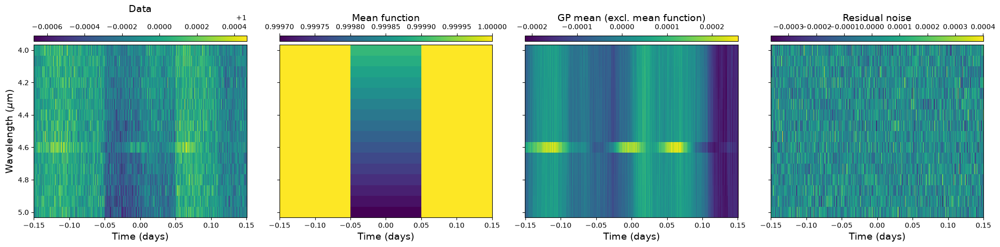


Runtime for log-likelihood calculation with MultiLowRankKernel:
4.86 ms ± 257 μs per loop (mean ± std. dev. of 7 runs, 1 loop each)


In [16]:
def kf_multilowrank(p, X):
    # Our kernel with measurement covariance from before
    s_l = luas.kernels.quasisep.Noise(jnp.exp(p["log_sigma"]))
    s_l += jnp.exp(2*p["log_h_readout"]) * luas.kernels.quasisep.Exp(jnp.exp(p["log_l_readout"]))
    s_t = luas.kernels.quasisep.KroneckerDelta()

    # Our kernel describing time-correlated noise which is constant in wavelength
    alpha_l1 = luas.kernels.lowrank.Constant(jnp.exp(p["log_h_const"]))
    k_t1 = luas.kernels.quasisep.Matern32(jnp.exp(p["log_l_t1"]))

    # Additional time-correlated systematics in the 10th light curve
    basis_vec = jnp.zeros(X[0].shape[-1])
    basis_vec = jnp.exp(p["log_h10"]) * basis_vec.at[9].set(1.)
    alpha_l2 = luas.kernels.lowrank.Amplitude(basis_vec)
    k_t2 = luas.kernels.quasisep.SquaredExpApprox(jnp.exp(p["log_l_t2"]))

    # Warning: Make sure to include the terms s_l, s_t first as they build invertible covariance matrices which luas will use
    # We simply include our new Kronecker product as a second tuple returned
    return (s_l, s_t), (alpha_l1, k_t1), (alpha_l2, k_t2)


# Feel free to play around with the dataset size to see runtime difference
N_l = 16    # Number of wavelengths
N_t = 1024  # Number of timepoints

x_l = np.linspace(4., 5., N_l)
x_t = jnp.linspace(-0.15, 0.15, N_t)
X = (x_l, x_t)

p_init = deepcopy(mfp)
p_init["fp_fs"] = np.linspace(100e-6, 300e-6, N_l)
p_init["Foot"] = 1.*np.ones(N_l)
p_init["Tgrad"] = 0.*np.ones(N_l)

hp = {
    "log_sigma":np.log(100e-6)*np.ones(N_l),

    "log_h_readout":np.log(30e-6),
    "log_l_readout":np.log(0.3),

    "log_h_const":np.log(80e-6),
    "log_l_t1":np.log(0.04),

    "log_h10":np.log(100e-6),
    "log_l_t2":np.log(0.02),
}
p_init.update(hp)

# luas will automatically identify the MultiLowRankKernel optimisation
gp = luas.GP(p_init, X, mf = eclipse_2D, kf = kf_multilowrank)

# Ensure a consistent noise draw
np.random.seed(42)

# sample from the GP prior again
Y = gp.sample(p_init, add_mf = True)

logP_val = gp.logP(p_init, Y)
print(f"Starting log-posterior value: {logP_val}")

# Visualise the simulated data and the initial GP fit to the data (in this case the GP fit has the optimal simulated parameters)
gp_mean, mf_model = gp.plot(p_init, Y, axes_labels = [r"Wavelength ($\mu$m)", r"Time (days)"], return_fit = True)
plt.show()

print("\nRuntime for log-likelihood calculation with MultiLowRankKernel:")
%timeit gp.logL(p_init, Y).block_until_ready()

Here you can visualise the approximation error in the quasiseparable squared exponential kernel we used in the previous cell. We can play around with the approximation order $J$, which corresponds to the quasiseparable rank of the covariance matrix, where the compute cost scales as ~$\mathcal{O}(NJ^2)$ for matrix decomposition. For this particular approximation, $J$ must be even, and $J>12$ risks numerical stability errors. Beyond the error in the kernel shape, all other calculations are exact, and any approximation order still guarantees a valid kernel function. $J = 6$ is the current default and is much closer to a squared exponential than common quasiseparable alternatives like e.g. Matern-5/2.

We also use this example to show how to build a 1D GP using ``luas``, note that we no longer use a ``tuple`` for the regression vectors, or for what the functions take as input or return.

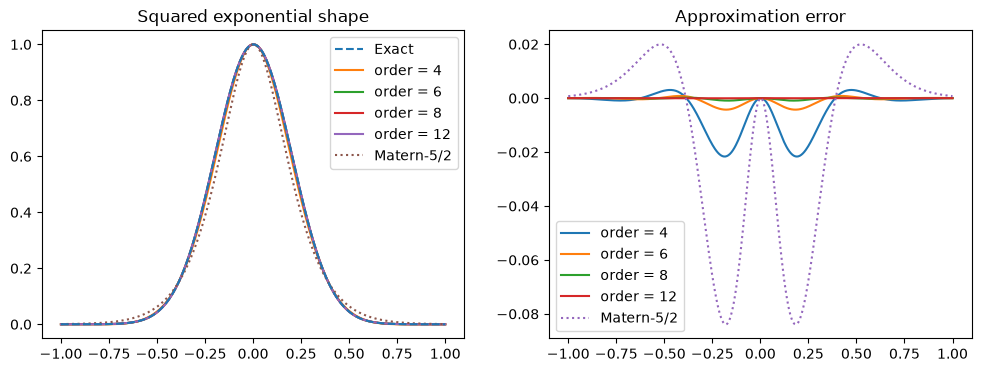

Using: General (1D)
Using: Quasiseparable (1D)

Exact squared exp fit:


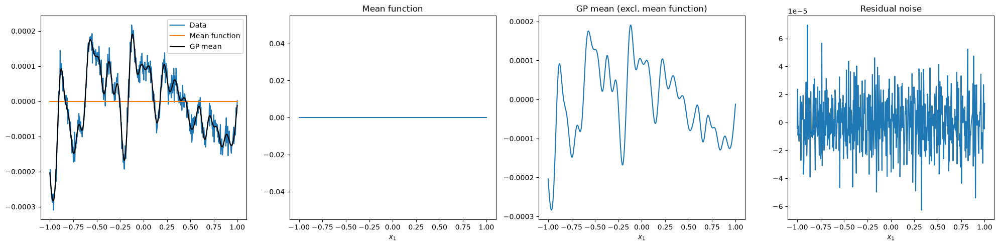


Quasiseparable approx squared exp fit:


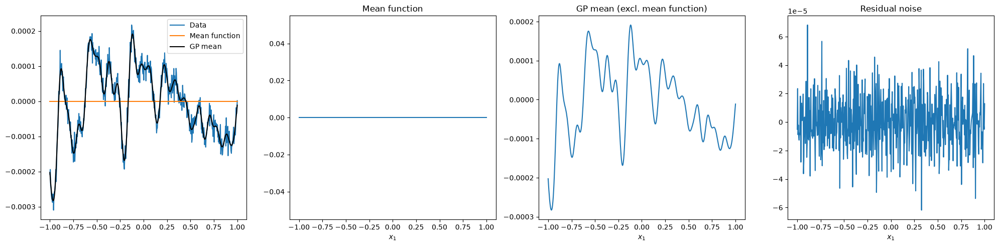

Starting log-posterior value: (exact) 4683.97999646298, (approx) 4682.939702997241


In [19]:
N = 1024  # Number of timepoints
x = jnp.linspace(-1., 1., 512)

# First visualise the approximation error of the quasisep squared exponential kernel
k_squaredexp_exact = luas.kernels.SquaredExp(0.2)
K_eval_exact = k_squaredexp_exact(x, x)


fig, ax = plt.subplots(1, 2, figsize = (12, 4))
ax[0].set_title("Squared exponential shape")
ax[1].set_title("Approximation error")
ax[0].plot(x, K_eval_exact[x.size//2, :], label = "Exact", linestyle = 'dashed', zorder = 10)

# Defaults to an approximation order of 6, but can be set higher
# avoid order > 12 for numerical stability, use even numbers only
approx_orders = [4, 6, 8, 12]

for approx_order in approx_orders:
    k_squaredexp_app = luas.kernels.quasisep.SquaredExpApprox(0.2, order = approx_order)
    K_eval_app = k_squaredexp_app(x, x)

    ax[0].plot(x, K_eval_app[x.size//2, :], label = f"order = {approx_order}")
    ax[1].plot(x, K_eval_app[x.size//2, :] - K_eval_exact[x.size//2, :], label = f"order = {approx_order}")

# Plot Matern-5/2 for a comparison
k_matern52 = luas.kernels.quasisep.Matern52(0.2)
K_eval_app = k_matern52(x, x)

ax[0].plot(x, K_eval_app[x.size//2, :], label = f"Matern-5/2", linestyle = "dotted")
ax[1].plot(x, K_eval_app[x.size//2, :] - K_eval_exact[x.size//2, :], label = f"Matern-5/2", linestyle = "dotted")


ax[0].legend()
ax[1].legend()
plt.show()

def kf_sqexp(p, x):
    K = luas.kernels.Noise(jnp.exp(p["log_sigma"]))
    K += jnp.exp(2*p["log_h"]) * luas.kernels.SquaredExp(jnp.exp(p["log_l_t"]))

    return K

def kf_quasi_sqexp(p, x):
    K = luas.kernels.quasisep.Noise(jnp.exp(p["log_sigma"]))
    K += jnp.exp(2*p["log_h"]) * luas.kernels.quasisep.SquaredExpApprox(jnp.exp(p["log_l_t"]))

    return K

p = {
    "log_sigma":np.log(20e-6),

    "log_h":np.log(80e-6),
    "log_l_t":np.log(0.04),
}

gp_sqexp_1D = luas.GP(p, x, kf = kf_sqexp)
gp_quasi_sqexp_1D = luas.GP(p, x, kf = kf_quasi_sqexp)
y_1D = gp_sqexp_1D.sample(p)

print("\nExact squared exp fit:")
gp_mean_exact, mf_model = gp_sqexp_1D.plot(p, y_1D, return_fit = True)
plt.show()

print("\nQuasiseparable approx squared exp fit:")
gp_mean_approx, mf_model = gp_quasi_sqexp_1D.plot(p, y_1D, return_fit = True)
plt.show()

logP_val_exact = gp_sqexp_1D.logP(p, y_1D)
logP_val_approx = gp_quasi_sqexp_1D.logP(p, y_1D)
print(f"Starting log-posterior value: (exact) {logP_val_exact}, (approx) {logP_val_approx}")

With our MultiLowRankKernel, we can also have low-rank terms with the dimensions flipped, i.e. multiple low-rank terms in time with kernel functions in wavelength. This could be useful for marginalising out a lot of linear parameters that we normally fit for in each wavelength, e.g. the amplitude of an exponential ramp, or baseline parameters like the flux out-of-baseline or a linear slope in time. Since a GP is additive and these effects are often multiplicative, it can be an approximation to marginalise over it with a GP. However, especially for normalised eclipse light curves, the variation in flux in the model is very small ~100s ppm, and the uncertainty in the baseline parameters is often <1%, so the overall effect of adding instead of multiplying can often be less than 1ppm.

Let's just do a model with an exponential ramp to account for initial settling (feel free to experiment with adding more terms). We will fit for the wavelength-dependent amplitude with a Matern-3/2 kernel in wavelength, accounting for somewhat gradual variation in settling. We will input the amplitude of the settling over time by building an exponential ramp vector with some decay length scale (not to be confused with an exponential kernel function!), and giving it to the `luas.kernels.lowrank.Amplitude` kernel:
$$
\begin{aligned}
    s_\lambda(\lambda, \lambda') &= \sigma^2(\lambda)\delta_{\lambda\lambda'} + h^2_\textrm{readout}\exp\left(-\frac{|\lambda - \lambda'|}{l_\textrm{readout}}\right) &\hspace{2em} s_t(t, t') &= \delta_{t t'} \\
    k_{\lambda_1}(\lambda, \lambda') &= h^2_\textrm{ramp}\text{Matérn-3/2}\left(-\frac{|\lambda - \lambda'|}{l_\mathrm{\lambda_{ramp}}}\right) &\hspace{2em} \mathbf{\beta}_{t, 1} &= \exp\left(-\frac{\mathbf{t} - t_0}{l_\mathrm{t_{ramp}}}\right)
\end{aligned}
$$

Using: LuasLasrachKernel/MultiLowRankKernel


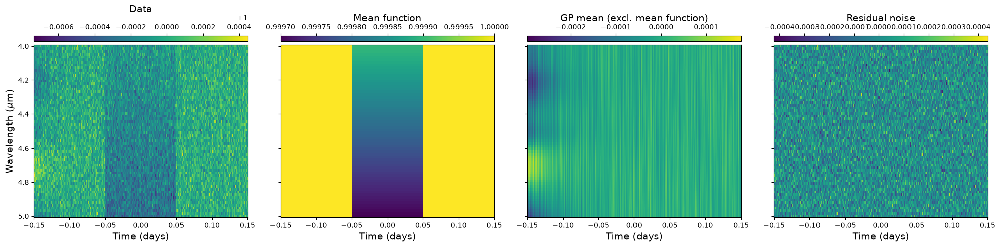

Runtime for log-likelihood calculation with MultiLowRankKernel:
158 μs ± 1.2 μs per loop (mean ± std. dev. of 7 runs, 10,000 loops each)


In [20]:
def kf_multilowranktime(p, X):
    # Our kernel with measurement covariance from before
    s_l = luas.kernels.quasisep.Noise(jnp.exp(p["log_sigma"]))
    s_l += jnp.exp(2*p["log_h_readout"]) * luas.kernels.quasisep.Exp(jnp.exp(p["log_l_readout"]))
    s_t = luas.kernels.quasisep.KroneckerDelta()

    # Our kernel describing detector settling which has an amplitude which is correlated in wavelength
    k_l1 = jnp.exp(2*p["log_h_ramp"]) * luas.kernels.quasisep.Matern32(jnp.exp(p["log_l_l_ramp"]))
    settle_vec = jnp.exp(-(X[1] - X[1][0])/jnp.exp(p["log_l_t_ramp"]))
    beta_t1 = luas.kernels.lowrank.Amplitude(settle_vec)

    # Warning: Make sure to include the terms s_l, s_t first as they build invertible covariance matrices which luas will use
    # We simply include our new Kronecker product as a second tuple returned
    return (s_l, s_t), (k_l1, beta_t1)

# Feel free to play around with the dataset size to see runtime difference
N_l = 64    # Number of wavelengths
N_t = 1024  # Number of timepoints

x_l = np.linspace(4., 5., N_l)
x_t = jnp.linspace(-0.15, 0.15, N_t)
X = (x_l, x_t)

p_init = deepcopy(mfp)
p_init["fp_fs"] = np.linspace(100e-6, 300e-6, N_l)
p_init["Foot"] = 1.*np.ones(N_l)
p_init["Tgrad"] = 0.*np.ones(N_l)

hp = {
    "log_sigma":np.log(100e-6)*np.ones(N_l),

    "log_h_readout":np.log(30e-6),
    "log_l_readout":np.log(0.3),

    "log_h_ramp":np.log(200e-6),
    "log_l_l_ramp":np.log(0.4),
    "log_l_t_ramp":np.log(0.03),
}
p_init.update(hp)

gp = luas.GP(p_init, X, mf = eclipse_2D, kf = kf_multilowranktime)

# Ensure a consistent noise draw
np.random.seed(42)

# sample from the GP prior again
Y = gp.sample(p_init, add_mf = True)

# Visualise the simulated data and the initial GP fit to the data (in this case the GP fit has the optimal simulated parameters)
gp.plot(p_init, Y, axes_labels = [r"Wavelength ($\mu$m)", r"Time (days)"])
plt.show()

print("Runtime for log-likelihood calculation with MultiLowRankKernel:")
%timeit gp.logL(p_init, Y).block_until_ready()

We can actually combine this with a 2D kernel very efficiently, as the ``LuasPlusMultiLowRankKernel`` can maintain quasiseparable matrix decompositions in the longer dimension so long as the low-rank amplitude terms are in the longer dimension, i.e. kernels like this scale linearly with time:
$$
\begin{equation}
    k(\lambda, \lambda', t, t') = s_\lambda(\lambda, \lambda')s_\mathrm{t; quasi}(t, t') + k_{\lambda}(\lambda, \lambda')k_\mathrm{t; quasi}(t, t') + \sum_{j=1}^{N_\beta}k_{\lambda_j}(\lambda, \lambda')\beta_j(t) \beta_j(t'),\nonumber
\end{equation}
$$
While kernels like this will not be able to exploit quasiseparability at all, even if all the time kernels are quasiseparable:
$$
\begin{equation}
    k(\lambda, \lambda', t, t') = s_\lambda(\lambda, \lambda')s_\mathrm{t}(t, t') + k_{\lambda}(\lambda, \lambda')k_\mathrm{t}(t, t') + \sum_{i=1}^{N_\alpha}\alpha_i(\lambda) \alpha_i(\lambda') k_{t_i}(t, t'),\nonumber
\end{equation}
$$
This is because an eigendecomposition of a time covariance matrix is needed in the latter case and so it will typically have a cubic scaling in time (it could however exploit quasiseparable kernels in wavelength, but this might be negligible if the time dimension is much longer).

Let's combine the detector settling kernel with the 2D correlation term from before, i.e.:

$$
\begin{aligned}
    s_\lambda(\lambda, \lambda') &= \sigma^2(\lambda)\delta_{\lambda\lambda'} + h^2_\textrm{readout}\exp\left(-\frac{|\lambda - \lambda'|}{l_\textrm{readout}}\right) &\hspace{2em} s_t(t, t') &= \delta_{t t'} \\
    k_\lambda(\lambda, \lambda') &= h^2 \text{Matérn}_{5/2}\left(-\frac{|\lambda - \lambda'|}{l_\lambda}\right) &\hspace{2em} k_{t}(t, t') &= \text{Matérn}_{3/2}\left(-\frac{|t - t'|}{l_{t}}\right)\\
    k_{\lambda_1}(\lambda, \lambda') &= h^2_\textrm{ramp}\text{Matérn-3/2}\left(-\frac{|\lambda - \lambda'|}{l_\mathrm{\lambda_{ramp}}}\right) &\hspace{2em} \mathbf{\beta}_{t, 1} &= \exp\left(-\frac{\mathbf{t} - t_0}{l_\mathrm{t_{ramp}}}\right)
\end{aligned}
$$

Using: LuasPlusMultiLowRankKernel


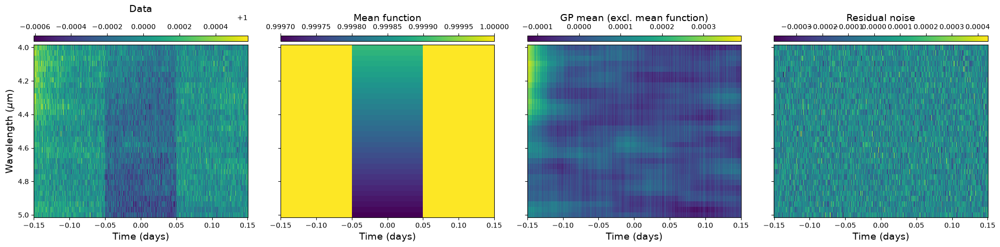

Runtime for log-likelihood calculation with LuasPlusMultiLowRankKernel:
3.19 ms ± 128 μs per loop (mean ± std. dev. of 7 runs, 1 loop each)


In [21]:
def kf_luaspluslowrank(p, X):
    # Our kernel with measurement covariance from before
    s_l = luas.kernels.quasisep.Noise(jnp.exp(p["log_sigma"]))
    s_l += jnp.exp(2*p["log_h_readout"]) * luas.kernels.quasisep.Exp(jnp.exp(p["log_l_readout"]))
    s_t = luas.kernels.quasisep.KroneckerDelta()

    # Our kernel describing 2D correlation in time and wavelength
    # switching the wavelength kernel to be quasiseparable makes no difference here as it must be eigendecomposed
    k_l = jnp.exp(2*p["log_h"]) * luas.kernels.Matern52(jnp.exp(p["log_l_l"]))

    # This is important to keep quasisep however for good scaling in time
    k_t = luas.kernels.quasisep.Matern32(jnp.exp(p["log_l_t"]))


    # Our kernel describing detector settling which has an amplitude which is correlated in wavelength
    k_l1 = jnp.exp(2*p["log_h_ramp"]) * luas.kernels.quasisep.Matern32(jnp.exp(p["log_l_l_ramp"]))
    settle_vec = jnp.exp(-(X[1] - X[1][0])/jnp.exp(p["log_l_t_ramp"]))
    beta_t1 = luas.kernels.lowrank.Amplitude(settle_vec)

    # Warning: Make sure to include the terms s_l, s_t first as they build invertible covariance matrices which luas will use
    # We simply include our new Kronecker product as a second tuple returned
    return (s_l, s_t), (k_l, k_t), (k_l1, beta_t1)


# Feel free to play around with the dataset size to see runtime difference
N_l = 32    # Number of wavelengths
N_t = 1024  # Number of timepoints

x_l = np.linspace(4., 5., N_l)
x_t = jnp.linspace(-0.15, 0.15, N_t)
X = (x_l, x_t)

p_init = deepcopy(mfp)
p_init["fp_fs"] = np.linspace(100e-6, 300e-6, N_l)
p_init["Foot"] = 1.*np.ones(N_l)
p_init["Tgrad"] = 0.*np.ones(N_l)

hp = {
    "log_sigma":np.log(100e-6)*np.ones(N_l),

    "log_h_readout":np.log(30e-6),
    "log_l_readout":np.log(0.3),

    "log_h":np.log(30e-6),
    "log_l_l":np.log(0.04),
    "log_l_t":np.log(0.04),

    "log_h_ramp":np.log(200e-6),
    "log_l_l_ramp":np.log(0.4),
    "log_l_t_ramp":np.log(0.03),
}
p_init.update(hp)

# luas will identify fast, exact optimisations to use on initialisation, but we are free to specify any valid one we wish
# Here we will force it to use LuasKernel, it will otherwise use MultiLowRankKernel which we will explain later
gp = luas.GP(p_init, X, mf = eclipse_2D, kf = kf_luaspluslowrank)

# Ensure a consistent noise draw
np.random.seed(42)

# sample from the GP prior again
Y = gp.sample(p_init, add_mf = True)

# Visualise the simulated data and the initial GP fit to the data (in this case the GP fit has the optimal simulated parameters)
gp.plot(p_init, Y, axes_labels = [r"Wavelength ($\mu$m)", r"Time (days)"])
plt.show()

print("Runtime for log-likelihood calculation with LuasPlusMultiLowRankKernel:")
%timeit gp.logL(p_init, Y).block_until_ready()

We can also combine low-rank kernels in both dimensions with the ``DoubleMultiLowRankKernel``, which can also exploit quasiseparable kernels in both dimensions provided we don't have any measurement covariance. So white noise with varying amplitude in time and wavelength is allowed, but correlations such as our readout noise term will mean the code can't exploit quasiseparable optimisations in that dimension (it should still work though, but with cubic wavelength scaling). This means we can get linear runtime scaling in both time and wavelength!

Let's combine our previous low-rank terms, accounting for common-mode systematics, systematics in the 10th light curve, and detector settling following an exponential decay at the beginning of the observation. Our kernel function looks like:
$$
\begin{equation}
    k(\lambda, \lambda', t, t') = s_\lambda(\lambda, \lambda') s_t(t, t') + \sum_{i=1}^{N_\alpha}\alpha_i(\lambda) \alpha_i(\lambda') k_{t_i}(t, t') + \sum_{j=1}^{N_\beta}k_{\lambda_j}(\lambda, \lambda')\beta_j(t) \beta_j(t'),
\end{equation}
$$
where we have (written as functions this time):
$$
\begin{aligned}
    s_\lambda(\lambda, \lambda') &= \sigma^2(\lambda)\delta_{\lambda\lambda'} + h^2_\textrm{readout}\exp\left(-\frac{|\lambda - \lambda'|}{l_\textrm{readout}}\right) &\hspace{2em} s_t(t, t') &= \delta_{t t'} \\
    \mathbf{\alpha}_1(\lambda) &= h_\mathrm{const} &\hspace{2em} k_{t_1}(t, t') &= \text{Matérn}_{3/2}\left(-\frac{|t - t'|}{l_{t_1}}\right)\\
    \mathbf{\alpha}_2(\lambda) &= h_\mathrm{10}\delta_{\lambda\lambda_{10}} &\hspace{2em} k_{t_2}(t, t') &= \exp\left(-\frac{|t - t'|^2}{l_{t_2}^2}\right)\\
    k_{\lambda_1}(\lambda, \lambda') &= h^2_\textrm{ramp}\text{Matérn-3/2}\left(-\frac{|\lambda - \lambda'|}{l_\mathrm{\lambda_{ramp}}}\right) &\hspace{2em} \beta_1(t) &= \exp\left(-\frac{\mathbf{t} - t_0}{l_\mathrm{t_{ramp}}}\right)
\end{aligned}
$$


Using: DoubleMultiLowRankKernel


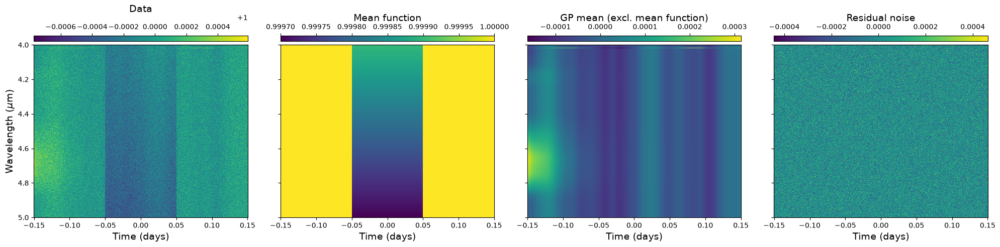

Runtime for log-likelihood calculation with DoubleMultiLowRankKernel:
4.94 ms ± 298 μs per loop (mean ± std. dev. of 7 runs, 1 loop each)


In [25]:
def kf_doublelowrankterms(p, X):
    # Our kernel with measurement covariance from before
    s_l = luas.kernels.quasisep.Noise(jnp.exp(p["log_sigma"]))

    # Comment out readout noise so quasiseparability can be exploited in wavelength dimension too
    # s_l += jnp.exp(2*p["log_h_readout"]) * luas.kernels.quasisep.Exp(jnp.exp(p["log_l_readout"]))

    s_t = luas.kernels.quasisep.KroneckerDelta()

    # Our kernel describing time-correlated noise which is constant in wavelength
    alpha_l1 = luas.kernels.lowrank.Constant(jnp.exp(p["log_h_const"]))
    k_t1 = luas.kernels.quasisep.Matern32(jnp.exp(p["log_l_t1"]))

    # Additional time-correlated systematics in the 10th light curve
    e_1 = jnp.zeros(X[0].shape[-1])
    e_1 = jnp.exp(p["log_h10"]) * e_1.at[9].set(1.)
    alpha_l2 = luas.kernels.lowrank.Amplitude(e_1)
    k_t2 = luas.kernels.quasisep.SquaredExpApprox(jnp.exp(p["log_l_t2"]))

    # Our kernel describing detector settling which has an amplitude which is correlated in wavelength
    k_l1 = jnp.exp(2*p["log_h_ramp"]) * luas.kernels.quasisep.Matern32(jnp.exp(p["log_l_l_ramp"]))
    settle_vec = jnp.exp(-(X[1] - X[1][0])/jnp.exp(p["log_l_t_ramp"]))
    beta_t1 = luas.kernels.lowrank.Amplitude(settle_vec)

    # Warning: Make sure to include the terms s_l, s_t first as they build invertible covariance matrices which luas will use
    # We simply include our new Kronecker product as a second tuple returned
    return (s_l, s_t), (alpha_l1, k_t1), (alpha_l2, k_t2), (k_l1, beta_t1)


# Feel free to play around with the dataset size to see runtime difference
N_l = 512    # Number of wavelengths
N_t = 512  # Number of timepoints

x_l = jnp.linspace(4., 5., N_l)
x_t = jnp.linspace(-0.15, 0.15, N_t)
X = (x_l, x_t)

p_init = deepcopy(mfp)
p_init["fp_fs"] = np.linspace(100e-6, 300e-6, N_l)
p_init["Foot"] = 1.*np.ones(N_l)
p_init["Tgrad"] = 0.*np.ones(N_l)

hp = {
    "log_sigma":np.log(100e-6)*np.ones(N_l),

    # Included if testing it with readout noise
    "log_h_readout":np.log(30e-6),
    "log_l_readout":np.log(0.3),

    "log_h_const":np.log(80e-6),
    "log_l_t1":np.log(0.04),

    "log_h10":np.log(100e-6),
    "log_l_t2":np.log(0.02),

    "log_h_ramp":np.log(200e-6),
    "log_l_l_ramp":np.log(0.4),
    "log_l_t_ramp":np.log(0.03),
}
p_init.update(hp)

# luas will automatically use the DoubleMultiLowRankKernel
gp = luas.GP(p_init, X, kf = kf_doublelowrankterms, mf = eclipse_2D)

# Ensure a consistent noise draw
np.random.seed(42)

# sample from the GP prior again
Y = gp.sample(p_init, add_mf = True)

# Visualise the simulated data and the initial GP fit to the data (in this case the GP fit has the optimal simulated parameters)
gp.plot(p_init, Y, axes_labels = [r"Wavelength ($\mu$m)", r"Time (days)"])
plt.show()

print("Runtime for log-likelihood calculation with DoubleMultiLowRankKernel:")
%timeit gp.logL(p_init, Y).block_until_ready()

Now to show the full flexibility of ``luas``, we'll put all these previous kernel terms together. The ``ExtendedLuasKernel`` doesn't scale amazingly well, scaling as ~$\mathcal{O}((1+N_\alpha^3) N_t^3 + (1+N_\beta^3) N_\lambda^3)$ in runtime, but for a small enough dataset it gives a very high level of flexibility at a doable speed. It should also run much faster on a GPU if you have that available. The full kernel function here is:
$$
\begin{equation}
    k(\lambda, \lambda', t, t') = s_\lambda(\lambda, \lambda') s_t(t, t') + k_{\lambda}(\lambda, \lambda')k_{t}(t, t') + \sum_{i=1}^{N_\alpha}\alpha_i(\lambda) \alpha_i(\lambda') k_{t_i}(t, t') + \sum_{j=1}^{N_\beta}k_{\lambda_j}(\lambda, \lambda')\beta_j(t) \beta_j(t'),
\end{equation}
$$
where we have (written as functions):
$$
\begin{aligned}
    s_\lambda(\lambda, \lambda') &= \sigma^2(\lambda)\delta_{\lambda\lambda'} + h^2_\textrm{readout}\exp\left(-\frac{|\lambda - \lambda'|}{l_\textrm{readout}}\right) &\hspace{2em} s_t(t, t') &= \delta_{t t'} \\
    k_\lambda(\lambda, \lambda') &= h_\lambda(\lambda)h_\lambda(\lambda') \text{Matérn}_{5/2}\left(-\frac{|\lambda - \lambda'|}{l_\lambda}\right) &\hspace{2em} k_{t}(t, t') &= \text{Matérn}_{3/2}\left(-\frac{|t - t'|}{l_{t}}\right)\\
    \mathbf{\alpha}_1(\lambda) &= h_\mathrm{const} &\hspace{2em} k_{t_1}(t, t') &= \text{Matérn}_{3/2}\left(-\frac{|t - t'|}{l_{t_1}}\right)\\
    \mathbf{\alpha}_2(\lambda) &= h_\mathrm{10}\delta_{\lambda\lambda_{10}} &\hspace{2em} k_{t_2}(t, t') &= \exp\left(-\frac{|t - t'|^2}{l_{t_2}^2}\right)\\
    k_{\lambda_1}(\lambda, \lambda') &= h^2_\textrm{ramp}\text{Matérn-3/2}\left(-\frac{|\lambda - \lambda'|}{l_\mathrm{\lambda_{ramp}}}\right) &\hspace{2em} \beta_1(t) &= \exp\left(-\frac{\mathbf{t} - t_0}{l_\mathrm{t_{ramp}}}\right)
\end{aligned}
$$
This kernel can't exploit quasiseparability, so we will switch the `luas.kernels.quasisep.SquaredExpApprox` kernel back to the exact `luas.kernels.SquaredExp` kernel, but there's no harm in keeping the `luas.kernels.quasisep` kernels for the other terms, they just aren't likely to run any faster than the base kernels in `luas.kernels`

Using: ExtendedLuasKernel


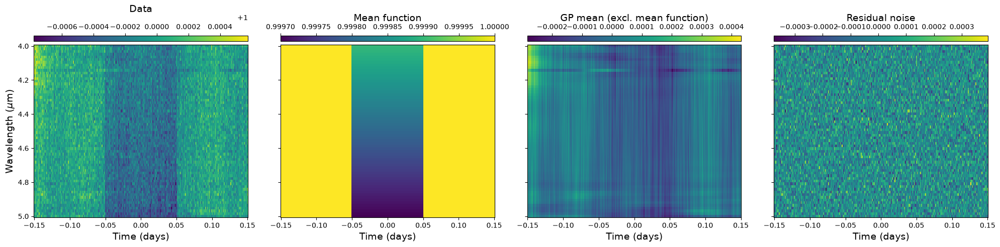

Runtime for log-likelihood calculation with Extended Luas Kernel:
11.2 ms ± 1.25 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


In [26]:
def kf_extendedluas(p, X):
    # Our kernel with measurement covariance from before
    s_l = luas.kernels.quasisep.Noise(jnp.exp(p["log_sigma"]))
    s_l += jnp.exp(2*p["log_h_readout"]) * luas.kernels.quasisep.Exp(jnp.exp(p["log_l_readout"]))
    s_t = luas.kernels.quasisep.KroneckerDelta()

    # Our kernel describing time-correlated noise which is constant in wavelength
    k_l = luas.kernels.lowrank.Amplitude(jnp.exp(p["log_h_l_vec"])) * luas.kernels.Matern52(jnp.exp(p["log_l_l"]))
    k_t = luas.kernels.quasisep.Matern32(jnp.exp(p["log_l_t"]))

    # Our kernel describing time-correlated noise which is constant in wavelength
    alpha_l1 = luas.kernels.lowrank.Constant(jnp.exp(p["log_h_const"]))
    k_t1 = luas.kernels.quasisep.Matern32(jnp.exp(p["log_l_t1"]))

    e_1 = jnp.zeros(X[0].shape[-1])
    e_1 = jnp.exp(p["log_h10"]) * e_1.at[9].set(1.)
    alpha_l2 = luas.kernels.lowrank.Amplitude(e_1)
    # Can't exploit quasisep kernels for this optimisation, so no point of approximate squared exp kernel
    k_t2 = luas.kernels.SquaredExp(jnp.exp(p["log_l_t2"]))

    # Our kernel describing detector settling which has an amplitude which is correlated in wavelength
    k_l1 = jnp.exp(2*p["log_h_ramp"]) * luas.kernels.quasisep.Matern32(jnp.exp(p["log_l_l_ramp"]))
    settle_vec = jnp.exp(-(X[1] - X[1][0])/jnp.exp(p["log_l_t_ramp"]))
    beta_t1 = luas.kernels.lowrank.Amplitude(settle_vec)

    # Warning: Make sure to include the terms s_l, s_t first as they build invertible covariance matrices which luas will use
    # We simply include our new Kronecker product as a second tuple returned
    return (s_l, s_t), (k_l, k_t), (alpha_l1, k_t1), (alpha_l2, k_t2), (k_l1, beta_t1)


# Feel free to play around with the dataset size to see runtime difference
N_l = 64    # Number of wavelengths
N_t = 256  # Number of timepoints

x_l = np.linspace(4., 5., N_l)
x_t = jnp.linspace(-0.15, 0.15, N_t)
X = (x_l, x_t)

p_init = deepcopy(mfp)
p_init["fp_fs"] = np.linspace(100e-6, 300e-6, N_l)
p_init["Foot"] = 1.*np.ones(N_l)
p_init["Tgrad"] = 0.*np.ones(N_l)

h_l_vec = 200e-6 * (X[0] - X[0].mean())**2 * np.ones(N_l)

hp = {
    "log_sigma":np.log(100e-6)*np.ones(N_l),

    "log_h_readout":np.log(40e-6),
    "log_l_readout":np.log(0.3),

    "log_h_l_vec":np.log(h_l_vec),
    "log_l_l":np.log(0.02),
    "log_l_t":np.log(0.04),

    "log_h_const":np.log(80e-6),
    "log_l_t1":np.log(0.04),

    "log_h10":np.log(100e-6),
    "log_l_t2":np.log(0.02),

    "log_h_ramp":np.log(200e-6),
    "log_l_l_ramp":np.log(0.4),
    "log_l_t_ramp":np.log(0.03),
}
p_init.update(hp)

# luas will automatically use the ExtendedLuasKernel
gp = luas.GP(p_init, X, mf = eclipse_2D, kf = kf_extendedluas)

# Ensure a consistent noise draw
np.random.seed(42)

# sample from the GP prior again
Y = gp.sample(p_init, add_mf = True)

# Visualise the simulated data and the initial GP fit to the data (in this case the GP fit has the optimal simulated parameters)
gp.plot(p_init, Y, axes_labels = [r"Wavelength ($\mu$m)", r"Time (days)"])
plt.show()

print("Runtime for log-likelihood calculation with Extended Luas Kernel:")
%timeit gp.logL(p_init, Y).block_until_ready()

We can once again plot this covariance matrix in terms of all its component covariance matrices

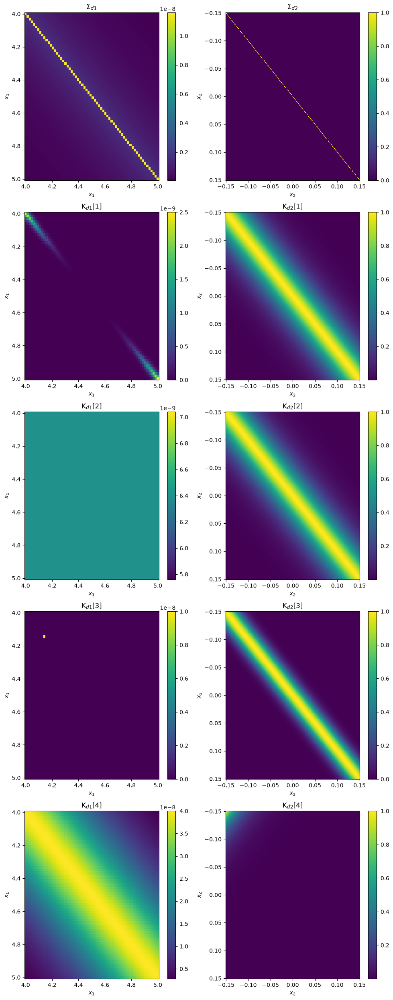

In [27]:
gp.plot_cov_mat(p_init)

BONUS: N-dimensional GPs!

The ``SeparableKernel``, ``LuasKernelND`` and ``LuasLasrachKernel`` all generalise to n-dimensions, so we can handle the kernel function being separable in each of the n-dimensions, or a sum of two kernels separable in each of the n-dimensions. I'm not really sure what a great use case for this is yet, since the white noise also has to be separable in each dimension this can be a major limitation for use cases such as different spectroscopic time-series/imaging time-series are treated as a 3D data cube to fit simultaneously. In many cases, it may be best to just treat things as a sum of independent 2D GPs. But here is an example, let me know if there's anything you're interested in using it for!

In [8]:


def kf_3D(p, X):
    # Some arbitrary third dimension where readout noise is independent
    s_m = luas.kernels.KroneckerDelta()

    s_l = luas.kernels.Noise(jnp.exp(p["log_sigma"]))
    # Can still include measurement covariance if you like
    # s_l += jnp.exp(2*p["log_h_readout"]) * luas.kernels.Exp(jnp.exp(p["log_l_readout"]))

    s_t = luas.kernels.KroneckerDelta()

    # 3D squared exponential kernel across the three dimensions
    k_m = jnp.exp(2 * p["log_h"]) * luas.kernels.SquaredExp(jnp.exp(p["log_l_m"]))
    k_l = luas.kernels.SquaredExp(jnp.exp(p["log_l_l"]))
    k_t = luas.kernels.SquaredExp(jnp.exp(p["log_l_t"]))

    # Warning: Make sure to include the terms s_l, s_t first as they build invertible covariance matrices
    # We simply include our new Kronecker product as a second returned tuple
    return (s_m, s_l, s_t), (k_m, k_l, k_t)

# Feel free to play around with the dataset size to see runtime difference
N_m = 64    # Length of third dimension
N_l = 32    # Number of wavelengths
N_t = 128  # Number of timepoints

x_m = np.linspace(0, N_m)
x_l = np.linspace(4., 5., N_l)
x_t = jnp.linspace(-0.15, 0.15, N_t)
X = (x_m, x_l, x_t)

p_init = deepcopy(mfp)
p_init["fp_fs"] = np.linspace(100e-6, 300e-6, N_l)
p_init["Foot"] = 1.*np.ones(N_l)
p_init["Tgrad"] = 0.*np.ones(N_l)

hp = {
    "log_sigma":np.log(100e-6)*np.ones(N_l),

    # If including measurement covariance
    "log_h_readout":np.log(30e-6),
    "log_l_readout":np.log(0.3),

    "log_h":np.log(80e-6),
    "log_l_m":np.log(0.1),
    "log_l_l":np.log(0.2),
    "log_l_t":np.log(0.01),
}
p_init.update(hp)

gp = luas.GP(p_init, X, kf = kf_3D)

# Ensure a consistent noise draw
np.random.seed(42)

# sample from the GP prior again
Y = gp.sample(p_init)

print("\nStarting log posterior value:", gp.logP(p_init, Y))

# 3D plotting uses pretty much AI slop code...
# but should be able to output an interactive HTML or a GIF provided datacube isn't too big
gp.plot(p_init, Y, axes_labels= ["Order", r"Wavelength ($\mu$m)", "Time (days)"])

For >2D with two Kronecker terms we currently default to LuasKernelND, but LuasLasrachKernel may be worth checking too!

Using: LuasKernelND

Starting log posterior value: 1586958.471034378


This concludes the walkthrough, if you would like to fit models/perform inference on parameters, then be sure to check out the later tutorials!